In [2]:
from pesummary.io import read;

from pycbc.inference.io import loadfile;
from pycbc import conversions as cvs;
from pycbc import cosmology as cos;

import numpy as np
import matplotlib.pyplot as pp
import seaborn as sns

import pandas as pd

pp.rcParams.update({
    "text.usetex": False,  # 启用 LaTeX 渲染
    # "font.family": "serif",  # 可选：设置字体为衬线字体（与 LaTeX 风格一致）
    # "font.serif": ["Times New Roman", "Computer Modern Roman"],  # 可选：指定字体
});
pp.rcParams.update(pp.rcParamsDefault);

def augment_OGC_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    # samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    # samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    # samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    # samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    temp = {}
    temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    samples = samples.add_fields(temp['spin1_z'], 'spin1_z')
    samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    samples = samples.add_fields(temp['spin2_z'], 'spin2_z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

def augment_OGC_XAS_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    # samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    # samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    def chi_hat_PN(m1,m2,chi1,chi2) :
        eta = cvs.eta_from_mass1_mass2(m1,m2)
        N = 1 - 76/133*eta
        chi_eff = cvs.chi_eff(m1,m2,chi1,chi2)
        term = -38/113*eta*(chi1+chi2)
        chi_PN = chi_eff + term
        return chi_PN / N
        # cvs.chi_eff(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z'])
    samples = samples.add_fields(chi_hat_PN(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z']), 'chi_hat_PN')
    
    # temp = {}
    # temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    # temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    # samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    # samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    # samples = samples.add_fields(samples['spin1z'], 'spin1z')
    # samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    # samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    # samples = samples.add_fields(samples['spin2z'], 'spin2z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [3]:
f = loadfile(f"/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_gr.hdf", "r")

In [4]:
# import h5py
# with h5py.File("/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_gr.hdf", 'r') as f:
#     # 查看0里面的子元素
#     print(f['config_file']['0'].keys())
#     # 继续读取深层数据
#     deep_data = f['config_file']['0']['子key名'][:]

In [5]:
import pickle
pickle.load(b''.join(f['config_file']['0'][:]))

TypeError: file must have 'read' and 'readline' attributes

In [ ]:
b''.join(f['config_file']['0'][:])

b'\x80\x05\x95z1\x8c\x03_io\x94\x8c\x08StringIO\x94\x93\x94)\x81\x94(XQ1[environment]\nPYTHON_BASIC_REPL = 1\nTMUX = /tmp/tmux-0/default,783,30\nCONDA_PROMPT_MODIFIER = (preload) \nUSER = root\nSSH_CLIENT = 59.64.32.75 59932 22\nGIT_ASKPASS = /root/.vscode-server/cli/servers/Stable-07ff9d6178ede9a1bd12ad3399074d726ebe6e43/server/extensions/git/dist/askpass.sh\nSHLVL = 1\nBROWSER = /root/.vscode-server/cli/servers/Stable-07ff9d6178ede9a1bd12ad3399074d726ebe6e43/server/bin/helpers/browser.sh\nHOME = /root\nCONDA_SHLVL = 2\nOLDPWD = /workspace\nTERM_PROGRAM_VERSION = 3.4\nVSCODE_IPC_HOOK_CLI = /tmp/vscode-ipc-b0660ba8-ac35-403b-b66f-dc4417cf43fd.sock\nGK_GL_PATH = /tmp/gitkraken/gitlens/gitlens-ipc-server-360-39693.json\nVSCODE_GIT_ASKPASS_MAIN = /root/.vscode-server/cli/servers/Stable-07ff9d6178ede9a1bd12ad3399074d726ebe6e43/server/extensions/git/dist/askpass-main.js\nVSCODE_GIT_ASKPASS_NODE = /root/.vscode-server/cli/servers/Stable-07ff9d6178ede9a1bd12ad3399074d726ebe6e43/server/node\nC

In [ ]:
cos.distance_from_comoving_volume([5e3,92918664351])

array([  10.6333434 , 5000.08294244])

In [ ]:
cos.distance_from_comoving_volume([1e8,3987662576,3987662576*3,92918664351])

array([ 306.97085013, 1215.48591016, 1915.60588749,
       5000.08294244])

In [ ]:
3987662576*3

11962987728

In [ ]:
cos.distance_from_comoving_volume([1e7,92918664351])

array([ 137.71624513, 5000.08294244])

In [6]:
samples = {}
fp = loadfile("/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC0/GW150914/OGC4-GW150914_gr.hdf", 'r')
samples = fp.read_samples(fp['samples'].keys())
samples = augment_OGC_result(samples)
samples = pd.DataFrame(samples)


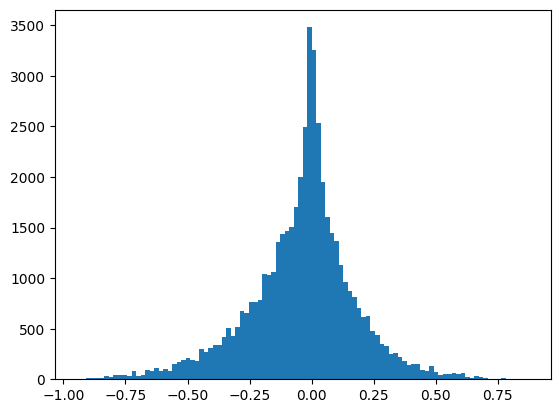

In [12]:
pp.hist(samples["spin2_z"], bins=100);

- **Median Ratio** $r(\{\psi_{j(l)}\})$:
\begin{aligned}
    r_{50}(\psi_{j(l)}) \coloneqq \frac{P_{50}(\{\psi_{j(l)}^\text{(param)}\})}{P_{50}(\{\psi_{j(l)}^\text{(GR)}\})}
\end{aligned}

- **Width** $w(\psi_{j(l)})$:
\begin{aligned}
    w_{5,95}(\psi_{j(l)}) \coloneqq P_{95}(\{\psi_{j(l)}\}) - P_{5}(\{\psi_{j(l)}\})
\end{aligned}

- **Width Ratio** $r_{5,95}(\psi_{j(l)})$:
\begin{aligned}
    r_{5,95}(\psi_{j(l)}) \coloneqq \frac{w_{5,95}(\psi_{j(l)}^\text{(param)})}{w_{5,95}(\psi_{j(l)}^\text{(GR)})}
\end{aligned}

- **Consistency Proximity** $d_\text{con}(\psi_{j(l)})$:
\begin{aligned}
    d_\text{con}(\psi_{j(l)}) \coloneqq \frac{P_{50}(\{\psi_{j(l)}^\text{(param)}\}) - P_{50}(\{\psi_{j(l)}^\text{(GR)}\})}{\frac{1}{2}(w(\{\psi_{j(l)}^\text{(param)}\}) + w(\{\psi_{j(l)}^\text{GR}\}))}
\end{aligned}

- 相容 $\Longleftrightarrow$ 所有参数后验分布一致 $\Longrightarrow$ PN系数分布一致

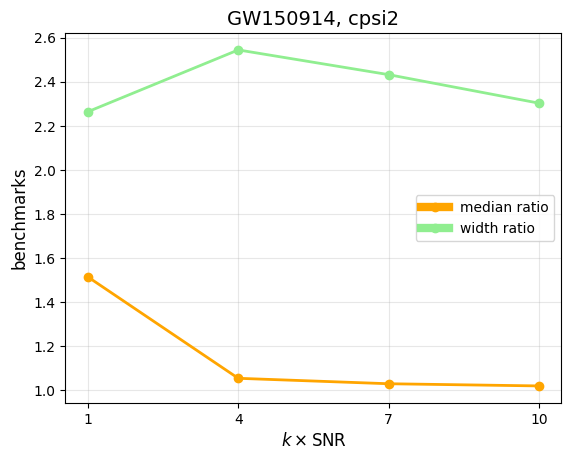

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ===================== 你的数据 =====================
times = [1, 4, 7, 10]  # 自定义横坐标
median_ratios = [1.5137, 1.0537, 1.029, 1.0191]
width_ratios = [2.2641, 2.5445, 2.4323, 2.3029]
# consistency_proximities = [1.7705, 0.6285, 0.7009, 0.5198]
# consistency_proximities = np.log10([1.7705, 0.6285, 0.7009, 0.5198])

# =====================================================

# 绘制两条折线
plt.plot(times, median_ratios, color="orange", linewidth=2, marker="o", markersize=6, label="median ratio")
plt.plot(times, width_ratios, color="lightgreen", linewidth=2, marker="o", markersize=6, label="width ratio")
# plt.plot(times, consistency_proximities, color="pink", linewidth=2, marker="o", markersize=6, label="consistency proximity")

# 🔥 核心修复：强制X轴只显示你指定的 1,4,7,10
plt.xticks(times)  

# 图表标签
plt.title("GW150914, cpsi2", fontsize=14)
plt.xlabel(r"$k \times$SNR", fontsize=12)
plt.ylabel("benchmarks", fontsize=12)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

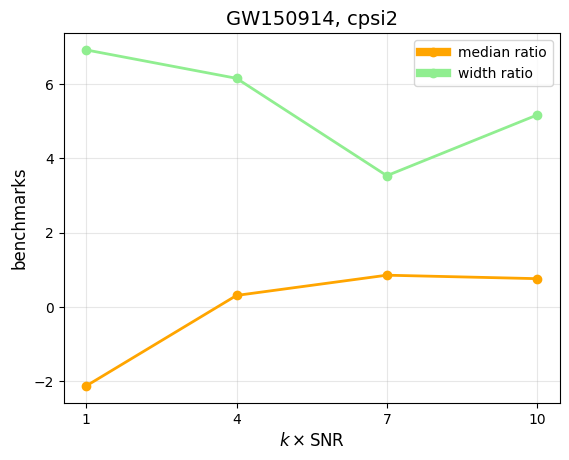

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ===================== 你的数据 =====================
times = [1, 4, 7, 10]  # 自定义横坐标
median_ratios = [-2.1298, 0.3085, 0.8541, 0.7607]
width_ratios = [6.9246, 6.1594, 3.5351, 5.1714]
# consistency_proximities = [1.7705, 0.6285, 0.7009, 0.5198]
# consistency_proximities = np.log10([1.7705, 0.6285, 0.7009, 0.5198])

# =====================================================

# 绘制两条折线
plt.plot(times, median_ratios, color="orange", linewidth=2, marker="o", markersize=6, label="median ratio")
plt.plot(times, width_ratios, color="lightgreen", linewidth=2, marker="o", markersize=6, label="width ratio")
# plt.plot(times, consistency_proximities, color="pink", linewidth=2, marker="o", markersize=6, label="consistency proximity")

# 🔥 核心修复：强制X轴只显示你指定的 1,4,7,10
plt.xticks(times)  

# 图表标签
plt.title("GW150914, cpsi2", fontsize=14)
plt.xlabel(r"$k \times$SNR", fontsize=12)
plt.ylabel("benchmarks", fontsize=12)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

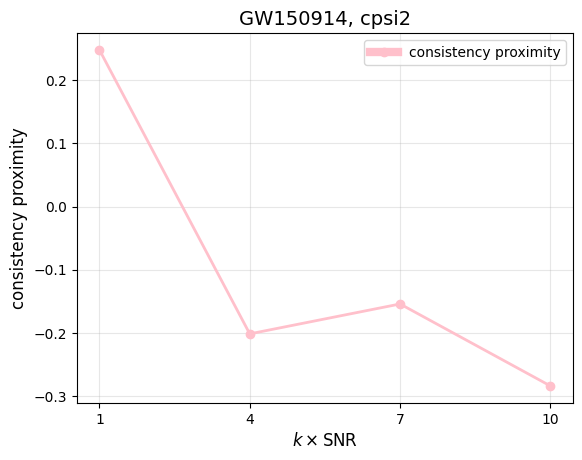

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ===================== 你的数据 =====================
times = [1, 4, 7, 10]  # 自定义横坐标
consistency_proximities = [1.7705, 0.6285, 0.7009, 0.5198]
consistency_proximities = np.log10(np.array([1.7705, 0.6285, 0.7009, 0.5198]))

# =====================================================

# 绘制两条折线
plt.plot(times, consistency_proximities, color="pink", linewidth=2, marker="o", markersize=6, label="consistency proximity")

# 🔥 核心修复：强制X轴只显示你指定的 1,4,7,10
plt.xticks(times)  

# 图表标签
plt.title("GW150914, cpsi2", fontsize=14)
plt.xlabel(r"$k \times$SNR", fontsize=12)
plt.ylabel("consistency proximity", fontsize=12)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

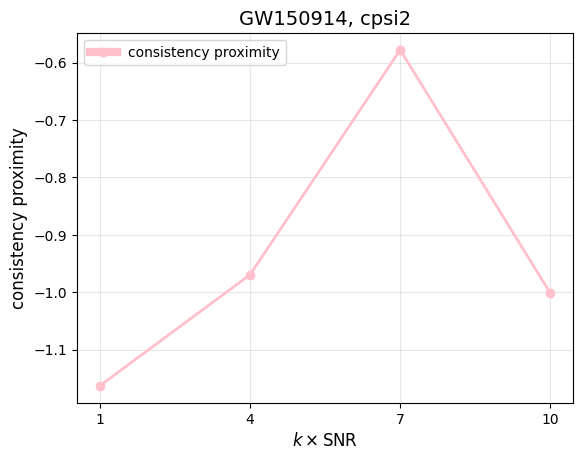

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ===================== 你的数据 =====================
times = [1, 4, 7, 10]  # 自定义横坐标
consistency_proximities = [-1.1634, -0.9699, -0.5778, -1.0021]
# consistency_proximities = np.log10(np.array(consistency_proximities))

# =====================================================

# 绘制两条折线
plt.plot(times, consistency_proximities, color="pink", linewidth=2, marker="o", markersize=6, label="consistency proximity")

# 🔥 核心修复：强制X轴只显示你指定的 1,4,7,10
plt.xticks(times)  

# 图表标签
plt.title("GW150914, cpsi2", fontsize=14)
plt.xlabel(r"$k \times$SNR", fontsize=12)
plt.ylabel("consistency proximity", fontsize=12)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

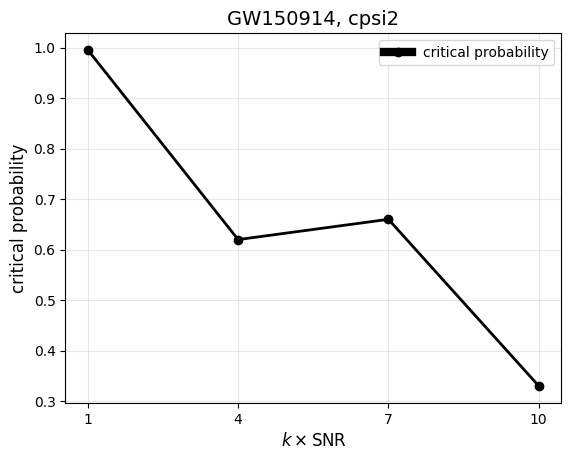

In [ ]:
import matplotlib.pyplot as plt

# ===================== 你的数据 =====================
times = [1, 4, 7, 10]  # 自定义横坐标
pcs = [0.995538, 0.62, 0.660119, 0.330234]

# =====================================================

# 绘制两条折线
plt.plot(times, pcs, color="black", linewidth=2, marker="o", markersize=6, label="critical probability")

# 🔥 核心修复：强制X轴只显示你指定的 1,4,7,10
plt.xticks(times)  

# 图表标签
plt.title("GW150914, cpsi2", fontsize=14)
plt.xlabel(r"$k \times$SNR", fontsize=12)
plt.ylabel("critical probability", fontsize=12)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
i = "7"

snrs = [1,4,7,10]
# snrs = [1,4]
# snr = 7

samples = {}


for s in snrs :
    # fp = loadfile("/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW170814/GW170814_gr.hdf", 'r')
    fp = loadfile(f"/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi{i}_SNR_{s}.hdf", 'r')
    samples = fp.read_samples(fp['samples'].keys())
    samples = augment_OGC_XAS_result(samples)
    samples = pd.DataFrame(samples)
    samples[["mass1","mass2","spin1z","spin2z","eta","Mchirp",f"dchi{i}"]].to_csv(f'/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW150914_095045/GW150914_095045_cpsi{i}_SNR_{s}.csv', index=False)

/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/pycbc/inference/io/__init__.py:415: SyntaxWarning: invalid escape sequence '\*'
  """Wraps argument parser, and preloads arguments needed for loading samples
/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/pycbc/inference/io/__init__.py:643: SyntaxWarning: invalid escape sequence '\*'
  """Loads an inference result file along with any labels associated with it


OSError: The file appears not to exist. In this case, filetype must be provided.

In [ ]:
i = "7"

snr = 10

samples = {}


fp = loadfile(f"/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/OGC/GW150914_095045/GW150914_095045_cpsi{i}_SNR_{snr}.hdf", 'r')
samples = fp.read_samples(fp['samples'].keys())
samples = augment_OGC_XAS_result(samples)
samples = pd.DataFrame(samples)
samples[["mass1","mass2","spin1z","spin2z","eta","Mchirp",f"dchi{i}"]].to_csv(f'/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW150914_095045/GW150914_095045_cpsi{i}_SNR_{snr}.csv', index=False)

In [ ]:
samples[[
        "mass1",
        "mass2",
        "spin1z",
        "spin2z",
        "inclination",
        "dec",
        "ra",
        "coa_phase",
        "distance",
        "redshift",
        f"dchi{i}"
        ]].median()

mass1          35.020710
mass2          29.182655
spin1z          0.070816
spin2z         -0.135464
inclination     2.476860
dec            -1.179842
ra              2.225620
coa_phase       2.758046
distance       45.637176
redshift        0.010232
dchi7           0.873037
dtype: float64

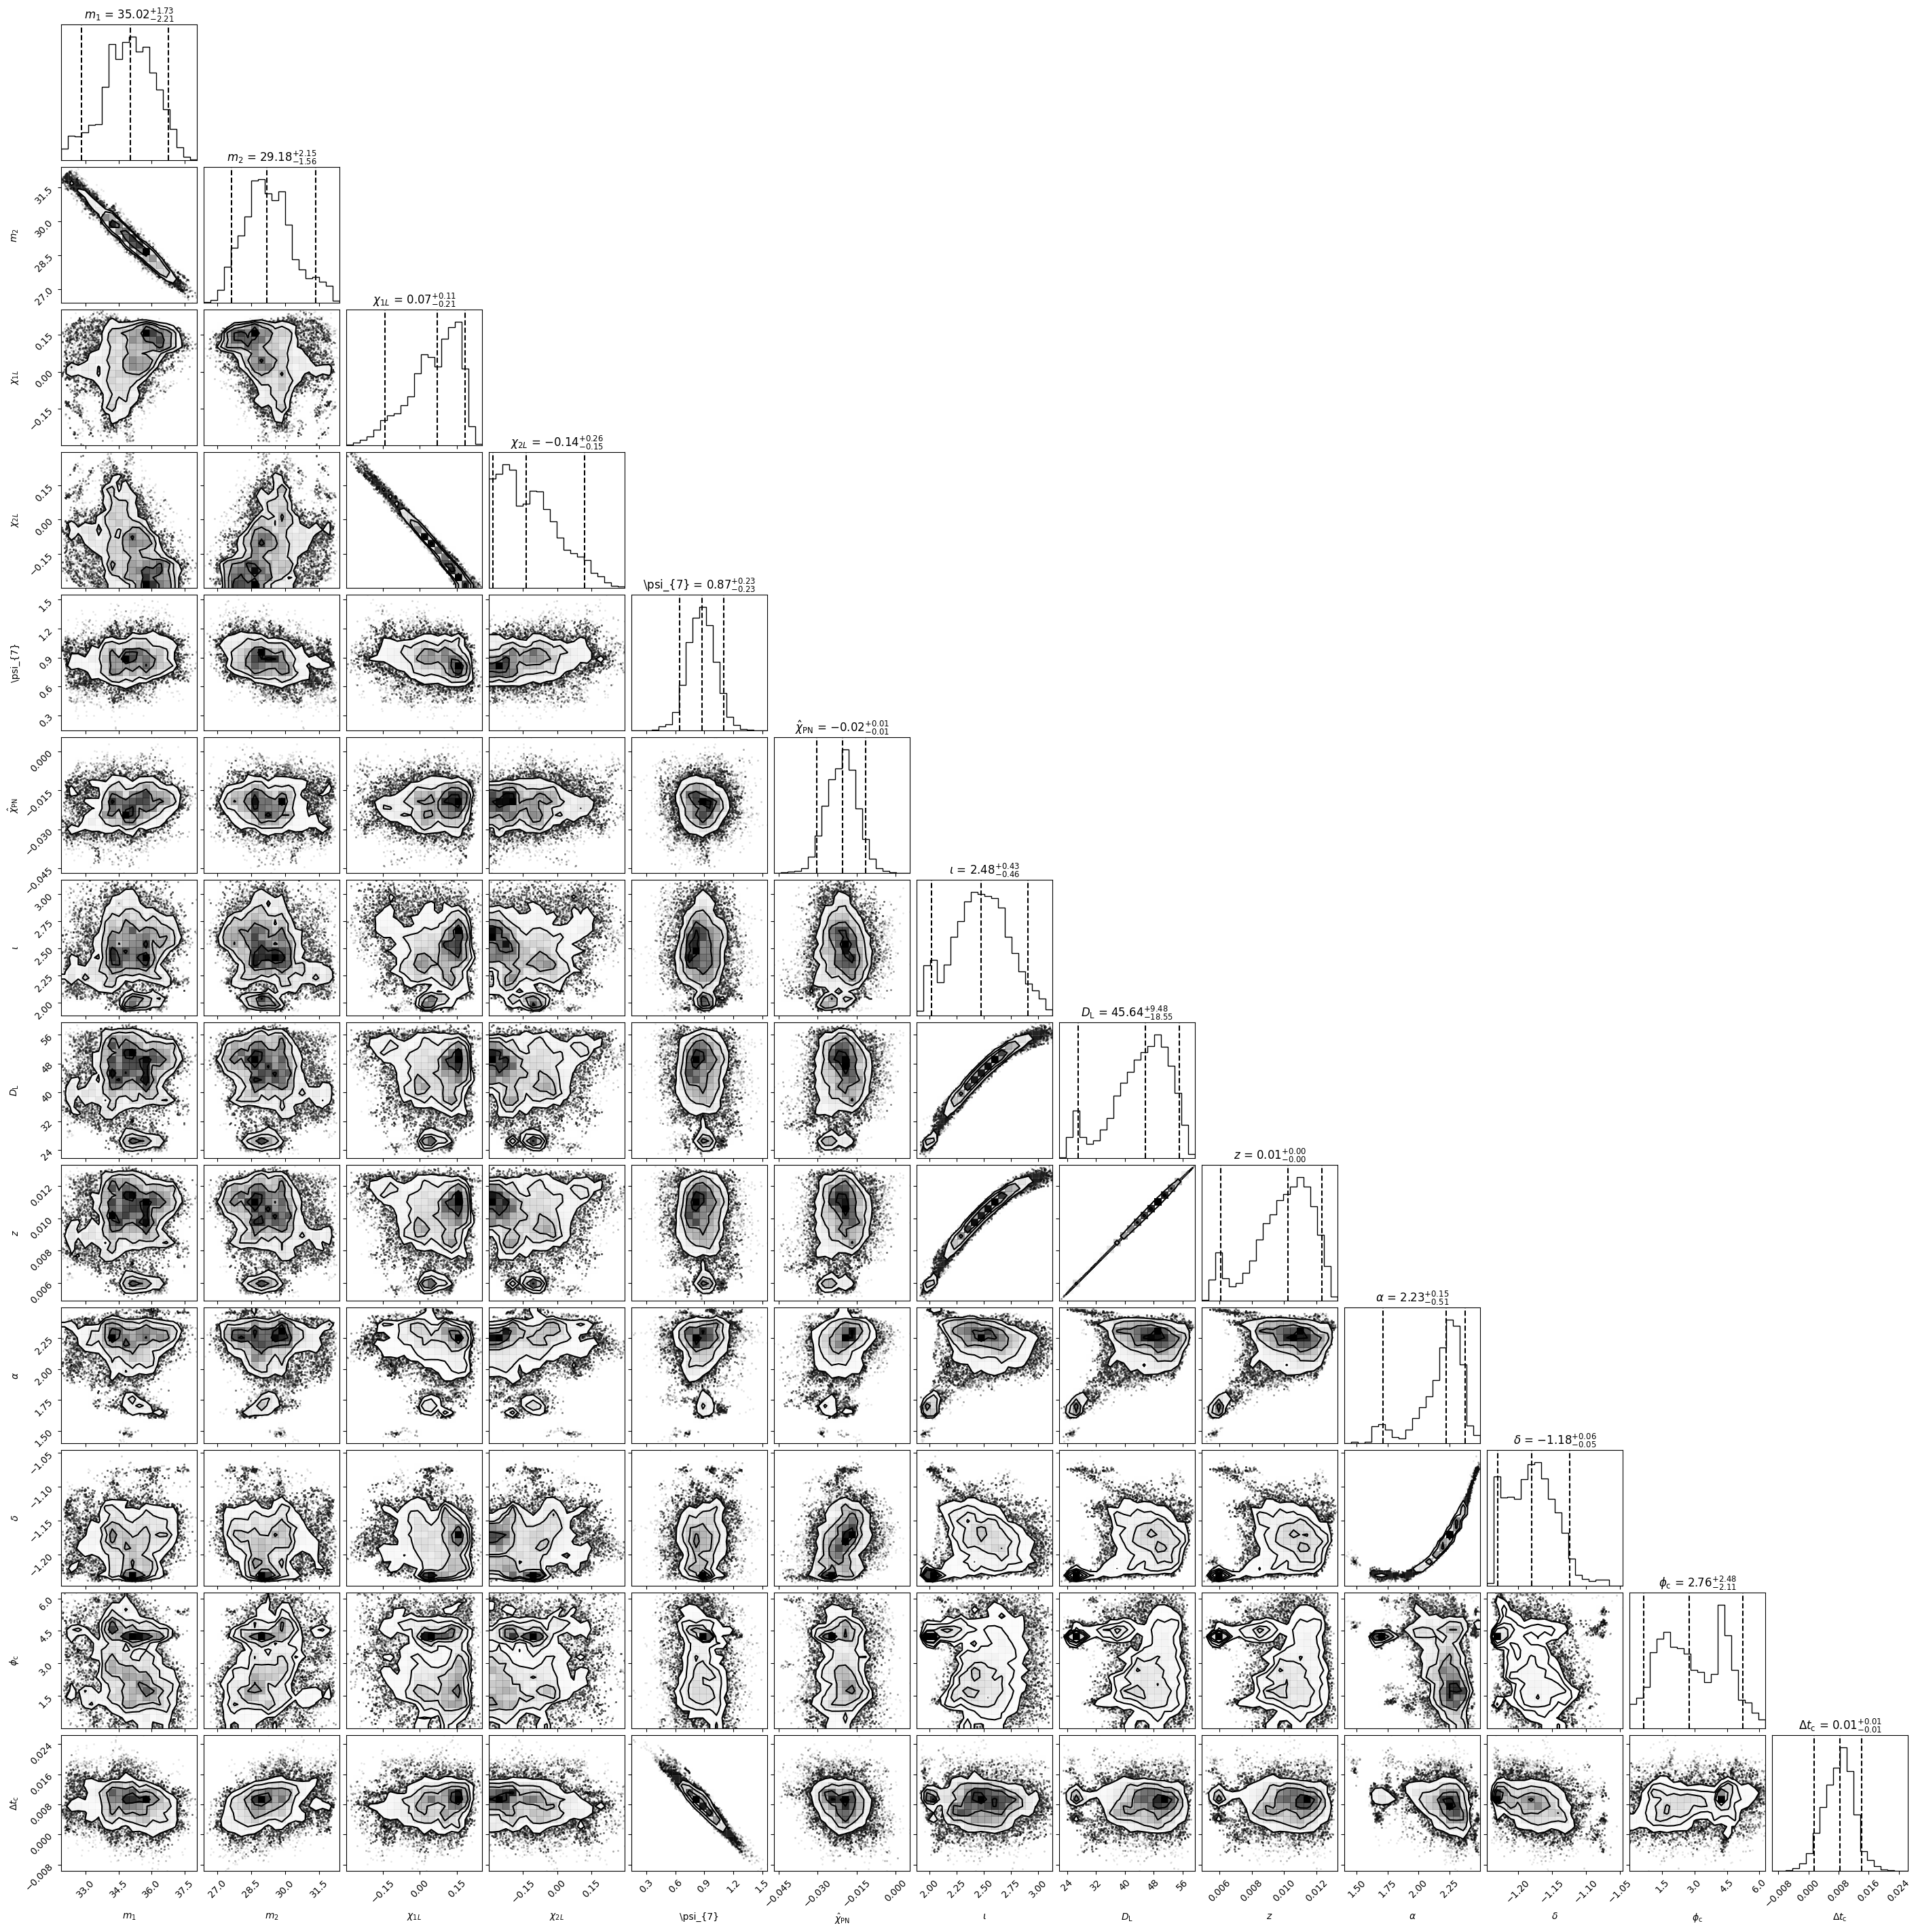

In [ ]:
import corner

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', f"dchi{i}", 'chi_hat_PN', 'inclination', 'distance', "redshift", "ra", "dec", 'coa_phase', "delta_tc"]
quantiles = [0.05, 0.50, 0.95]
corner.corner(samples[par_list],
                quantiles=quantiles,
                show_titles=True,
                hist_kwargs={"density": True},
                labels=[r"$m_1$",r"$m_2$",r"$\chi_{1L}$",r"$\chi_{2L}$", f"\\psi_{{{i}}}", r"$\hat{\chi}_\text{PN}$", r"$\iota$", r"$D_\text{L}$", r"$z$", r"$\alpha$", r"$\delta$", r"$\phi_\text{c}$", r"$\Delta t_\text{c}$"])


In [ ]:
import corner

par_list = ['mass1', 'mass2', 'spin1z', 'spin2z', 'chi_hat_PN', 'inclination', 'distance', "redshift", "ra", "dec", 'coa_phase', "delta_tc"]
quantiles = [0.05, 0.50, 0.95]
corner.corner(samples[par_list],
                quantiles=quantiles,
                show_titles=True,
                hist_kwargs={"density": True},
                labels=[r"$m_1$",r"$m_2$",r"$\chi_{1L}$",r"$\chi_{2L}$", r"$\hat{\chi}_\text{PN}$", r"$\iota$", r"$D_\text{L}$", r"$z$", r"$\alpha$", r"$\delta$", r"$\phi_\text{c}$", r"$\Delta t_\text{c}$"]);


In [ ]:
pp.hist(samples["distance"],bins=50);

In [ ]:
pp.hist(samples["mass1"],bins=100);

In [ ]:
pp.hist(samples["mass2"],bins=100);

In [ ]:
pp.hist(samples["inclination"],bins=50);

In [ ]:
pp.hist(samples["redshift"],bins=50);

In [ ]:
[
    cvs.mchirp_from_mass1_mass2(35,29),
    cvs.q_from_mass1_mass2(35,29)
]

[27.710453320983692, 1.206896551724138]

In [ ]:
[
    cvs.mchirp_from_mass1_mass2(samples["mass1"].median(), samples["mass2"].median()),
    cvs.q_from_mass1_mass2(samples["mass1"].median(), samples["mass2"].median())
]

[27.80726603099972, 1.2000522471285315]

In [ ]:
from pycbc import dq

# 您的PSD时间窗口
psd_start = 1126259190.43
psd_end = 1126259702.43

# 查询H1_DATA标志
h1_data = {
  "dataset": "O1",
  "start": 1126259394,
  "id": "H1_DATA",
  "end": 1126259496,
  "segments": [
    [
      1126259394,
      1126259496
    ]
  ]
}
# {
#   "dataset": "O1",
#   "start": 1126259190,
#   "id": "H1_DATA",
#   "end": 1126259702,
#   "segments": [
#     [
#       1126259190,
#       1126259702
#     ]
#   ]
# }
# dq.query_flag('H1', 'DATA', int(psd_start), int(psd_end))
print(f"H1 DATA可用时间段: {h1_data}")

# 检查是否有覆盖
if len(h1_data) == 0:
    print("❌ 没有有效的H1数据！")
else:
    print(f"✅ 有{len(h1_data)}个有效数据段")
    for seg in h1_data:
        print(f"  {seg[0]} 到 {seg[1]}")


H1 DATA可用时间段: {'dataset': 'O1', 'start': 1126259394, 'id': 'H1_DATA', 'end': 1126259496, 'segments': [[1126259394, 1126259496]]}
✅ 有5个有效数据段
  d 到 a
  s 到 t
  i 到 d
  e 到 n
  s 到 e
